# AI Fundamentals Coding Challenge

**Nama:** _(Reikananta Fauziah Lazuardi)_   
**Tanggal:** _(13 Oktober 2026)_  
**Link Dataset yang digunakan:** _(Climate Data Daily IDN (BMKG via Kaggle, https://www.kaggle.com/datasets/greegtitan/indonesia-climate) + kolom rumah tangga simulasi.)_

---
## Daftar Isi
1. [Challenge 1 - Data Exploration](#challenge-1)
2. [Challenge 2 - Machine Learning](#challenge-2)
3. [Challenge 3 - Prediction](#challenge-3)
4. [Challenge 4 - Integrasi Gemini API](#challenge-4)
5. [Challenge 5 - Responsible AI Reflection](#challenge-5)

## Setup Awal


In [ ]:
import os
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
%matplotlib inline

RANDOM_STATE = 1082026

print("Setup berhasil. Library siap digunakan.")


Setup berhasil. Library siap digunakan.


In [ ]:

import os

# Periksa folder utama di Google Drive
MYDRIVE = "/content/drive/MyDrive"

print("Folder yang tersedia di My Drive:\n")

for item in os.listdir(MYDRIVE):
    if os.path.isdir(os.path.join(MYDRIVE, item)):
        print(repr(item))

Folder yang tersedia di My Drive:

'TUGAS KULIAH'
'Sertifikat'
'Video TLM-LS'
'UAS INGGRIS'
'Karya Tulis'
'BEM KEMENSOS'
'CV'
'AMA Session : Career Preparation (09 08 2025) Reika'
'Lembar Kerja Akhir Link Women'
'Project LinkedIn'
'YaRi'
'PI Google Colab Project'
'Colab Notebooks'
'Kode Landing Page Renasih'
'PI Project '
'Website Ultah Mas Hilmi'
'Tampilan Assignment Local vs. Global State, React Context & Form Interaction'
'AI Fundamental Coding Assignment'


In [ ]:

import os

SEARCH_ROOT = "/content/drive/MyDrive/PI Google Colab Project"
TARGET_FILE = "BMKG_curah_hujan_bulanan_dataset.csv"

found_files = []

if os.path.isdir(SEARCH_ROOT):
    for root, dirs, files in os.walk(SEARCH_ROOT):
        if TARGET_FILE in files:
            found_files.append(os.path.join(root, TARGET_FILE))
else:
    print("Folder proyek tidak ditemukan:", SEARCH_ROOT)

if found_files:
    print("Dataset ditemukan pada lokasi berikut:\n")
    for path in found_files:
        print(path)
else:
    print(
        "Dataset belum ditemukan.\n"
        "Pastikan file CSV sudah diunggah ke Google Drive "
        "dan berada di dalam folder PI Google Colab Project."
    )

Dataset ditemukan pada lokasi berikut:

/content/drive/MyDrive/PI Google Colab Project/AI_Coding_Assignment_Reika_ /data/BMKG_curah_hujan_bulanan_dataset.csv


---
<a id='challenge-1'></a>
## Challenge 1 - Data Exploration (Pandas)


In [ ]:

# Soal 1.1: Muat dataset BMKG

import os
import pandas as pd

if not found_files:
    raise FileNotFoundError(
        "Dataset belum ditemukan. Jalankan langkah pencarian CSV terlebih dahulu."
    )

if len(found_files) > 1:
    print("Ditemukan lebih dari satu file dengan nama yang sama:")
    for i, path in enumerate(found_files, start=1):
        print(f"{i}. {path}")
    print("\nMenggunakan file pertama. Pastikan lokasinya benar.")

DATA_PATH = found_files[0]

df = pd.read_csv(DATA_PATH)

if df.empty:
    raise ValueError("Dataset kosong.")

df.columns = df.columns.str.strip()

print("Dataset berhasil dimuat!")
print("Lokasi:", DATA_PATH)
print("Jumlah baris:", f"{df.shape[0]:,}")
print("Jumlah kolom:", df.shape[1])

display(df.head())


Dataset berhasil dimuat!
Lokasi: /content/drive/MyDrive/PI Google Colab Project/AI_Coding_Assignment_Reika_ /data/BMKG_curah_hujan_bulanan_dataset.csv
Jumlah baris: 9,351
Jumlah kolom: 17


,stasiun_id,tahun,bulan,curah_hujan_bulan_lalu_mm,curah_hujan_2_bulan_lalu_mm,curah_hujan_bulan_sama_tahun_lalu_mm,hari_hujan_bulan_lalu,hari_kering_beruntun_maks_bulan_lalu,kelembapan_rata2_bulan_lalu_persen,suhu_rata2_bulan_lalu_c,suhu_min_rata2_bulan_lalu_c,suhu_maks_rata2_bulan_lalu_c,lama_penyinaran_rata2_bulan_lalu_jam,kecepatan_angin_rata2_bulan_lalu_ms,kecepatan_angin_maks_rata2_bulan_lalu_ms,curah_hujan_bulan_ini_mm,kategori_curah_hujan_bulan_ini
0,96001,2010,2,205.00,NaN,NaN,17.0,3.0,89.00,26.49,21.21,29.92,0.45,4.33,5.85,55.00,Rendah
1,96001,2010,3,55.00,205.00,NaN,4.0,12.0,86.61,27.39,21.90,31.21,0.44,4.46,6.25,88.87,Rendah
2,96001,2010,4,88.87,55.00,NaN,10.0,7.0,88.35,27.40,22.21,30.92,0.41,4.11,5.07,76.00,Rendah
3,96001,2010,5,76.00,88.87,NaN,7.0,17.0,88.40,28.34,22.79,32.13,0.37,3.83,4.83,52.00,Rendah
4,96001,2010,6,52.00,76.00,NaN,8.0,10.0,86.45,28.71,23.36,32.66,0.38,4.04,5.70,303.00,Tinggi


In [ ]:
# Soal 1.2: Informasi umum dataset

import pandas as pd
import numpy as np
from IPython.display import display


if "df" not in globals():
    raise NameError("Variabel df belum tersedia. Jalankan tahap 1.1 terlebih dahulu.")

# 1. Informasi dasar dataset
print("=" * 60)
print("INFORMASI DASAR DATASET BMKG")
print("=" * 60)
print(f"Jumlah baris       : {df.shape[0]:,}")
print(f"Jumlah kolom       : {df.shape[1]}")
print(f"Jumlah data duplikat: {df.duplicated().sum():,}")

# 2. Struktur dan tipe data
print("\n" + "=" * 60)
print("TIPE DATA SETIAP KOLOM")
print("=" * 60)
df.info()

# 3. Ringkasan nilai kosong
print("\n" + "=" * 60)
print("ANALISIS MISSING VALUES")
print("=" * 60)

missing_summary = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase Missing (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Jumlah Missing", ascending=False
)

display(missing_summary)

# 4. Statistik deskriptif kolom numerik
print("\n" + "=" * 60)
print("STATISTIK DESKRIPTIF")
print("=" * 60)
display(df.describe().T)

# 5. Jumlah nilai unik pada setiap kolom
print("\n" + "=" * 60)
print("JUMLAH NILAI UNIK")
print("=" * 60)

unique_summary = pd.DataFrame({
    "Jumlah Nilai Unik": df.nunique(dropna=True),
    "Contoh Nilai": [
        df[col].dropna().astype(str).unique()[:5].tolist()
        for col in df.columns
    ]
})

display(unique_summary)

INFORMASI DASAR DATASET BMKG
Jumlah baris       : 9,351
Jumlah kolom       : 17
Jumlah data duplikat: 0

TIPE DATA SETIAP KOLOM
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9351 entries, 0 to 9350
Data columns (total 17 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   stasiun_id                                9351 non-null   int64  
 1   tahun                                     9351 non-null   int64  
 2   bulan                                     9351 non-null   int64  
 3   curah_hujan_bulan_lalu_mm                 9351 non-null   float64
 4   curah_hujan_2_bulan_lalu_mm               8225 non-null   float64
 5   curah_hujan_bulan_sama_tahun_lalu_mm      6412 non-null   float64
 6   hari_hujan_bulan_lalu                     9351 non-null   float64
 7   hari_kering_beruntun_maks_bulan_lalu      9351 non-null   float64
 8   kelembapan_rata2_bulan_lalu_persen        9237 non

,Jumlah Missing,Persentase Missing (%)
curah_hujan_bulan_sama_tahun_lalu_mm,2939,31.43
curah_hujan_2_bulan_lalu_mm,1126,12.04
lama_penyinaran_rata2_bulan_lalu_jam,264,2.82
kecepatan_angin_rata2_bulan_lalu_ms,192,2.05
kecepatan_angin_maks_rata2_bulan_lalu_ms,190,2.03
kelembapan_rata2_bulan_lalu_persen,114,1.22
suhu_maks_rata2_bulan_lalu_c,114,1.22
suhu_rata2_bulan_lalu_c,84,0.90
suhu_min_rata2_bulan_lalu_c,53,0.57
stasiun_id,0,0.00



STATISTIK DESKRIPTIF


,count,mean,std,min,25%,50%,75%,max
stasiun_id,9351.0,96820.696931,529.945160,96001.00,96295.000,96783.000,97234.000,97980.00
tahun,9351.0,2013.873703,3.226426,2010.00,2011.000,2013.000,2017.000,2020.00
bulan,9351.0,6.676184,3.429964,1.00,4.000,7.000,10.000,12.00
curah_hujan_bulan_lalu_mm,9351.0,232.834666,180.429059,0.00,96.735,208.800,331.160,1766.50
curah_hujan_2_bulan_lalu_mm,8225.0,225.760426,177.012916,0.00,90.620,202.400,322.840,1766.50
curah_hujan_bulan_sama_tahun_lalu_mm,6412.0,240.059687,181.550594,0.00,106.000,216.075,338.925,1766.50
hari_hujan_bulan_lalu,9351.0,12.974013,6.853148,0.00,8.000,14.000,18.000,30.00
hari_kering_beruntun_maks_bulan_lalu,9351.0,7.150893,6.614440,0.00,3.000,5.000,9.000,31.00
kelembapan_rata2_bulan_lalu_persen,9237.0,82.387034,5.389177,56.18,79.680,83.390,86.030,95.65
suhu_rata2_bulan_lalu_c,9267.0,26.843371,1.645042,17.18,26.460,27.120,27.730,31.38



JUMLAH NILAI UNIK


,Jumlah Nilai Unik,Contoh Nilai
stasiun_id,168,"[96001, 96009, 96011, 96015, 96017]"
tahun,11,"[2010, 2011, 2012, 2013, 2016]"
bulan,12,"[2, 3, 4, 5, 6]"
curah_hujan_bulan_lalu_mm,7143,"[205.0, 55.0, 88.87, 76.0, 52.0]"
curah_hujan_2_bulan_lalu_mm,6327,"[205.0, 55.0, 88.87, 76.0, 52.0]"
curah_hujan_bulan_sama_tahun_lalu_mm,5217,"[205.0, 55.0, 88.87, 76.0, 52.0]"
hari_hujan_bulan_lalu,31,"[17.0, 4.0, 10.0, 7.0, 8.0]"
hari_kering_beruntun_maks_bulan_lalu,32,"[3.0, 12.0, 7.0, 17.0, 10.0]"
kelembapan_rata2_bulan_lalu_persen,1801,"[89.0, 86.61, 88.35, 88.4, 86.45]"
suhu_rata2_bulan_lalu_c,911,"[26.49, 27.39, 27.4, 28.34, 28.71]"


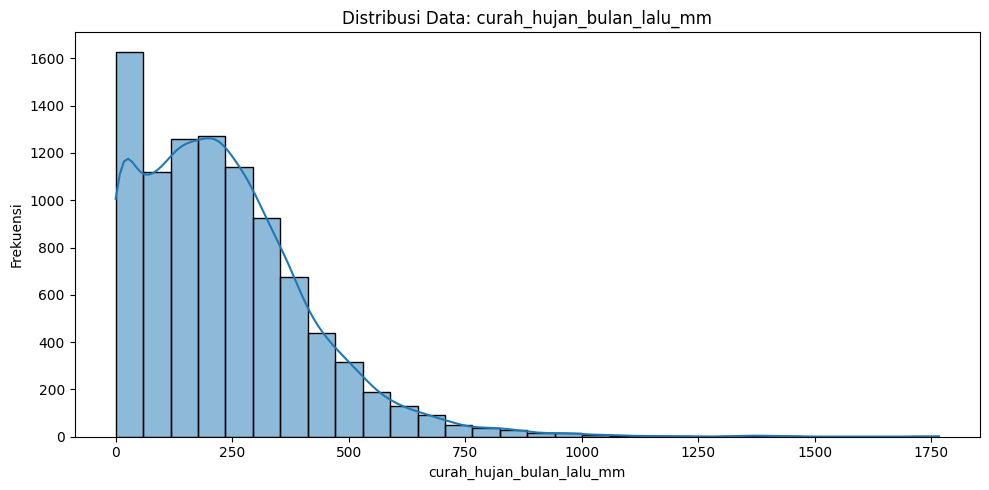

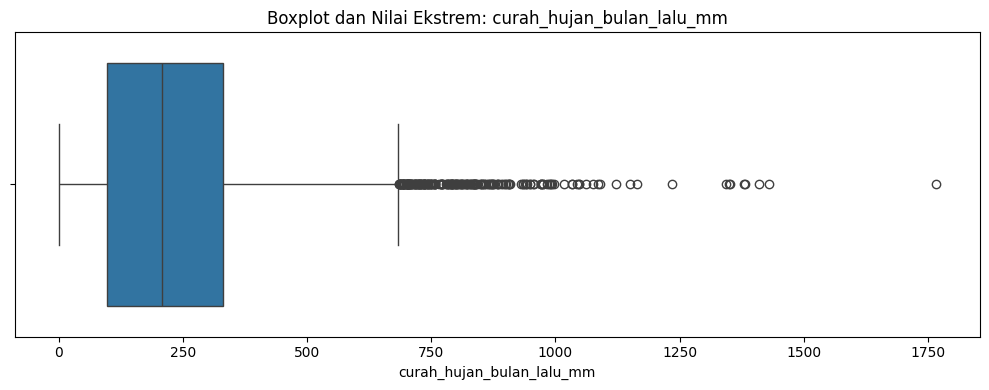

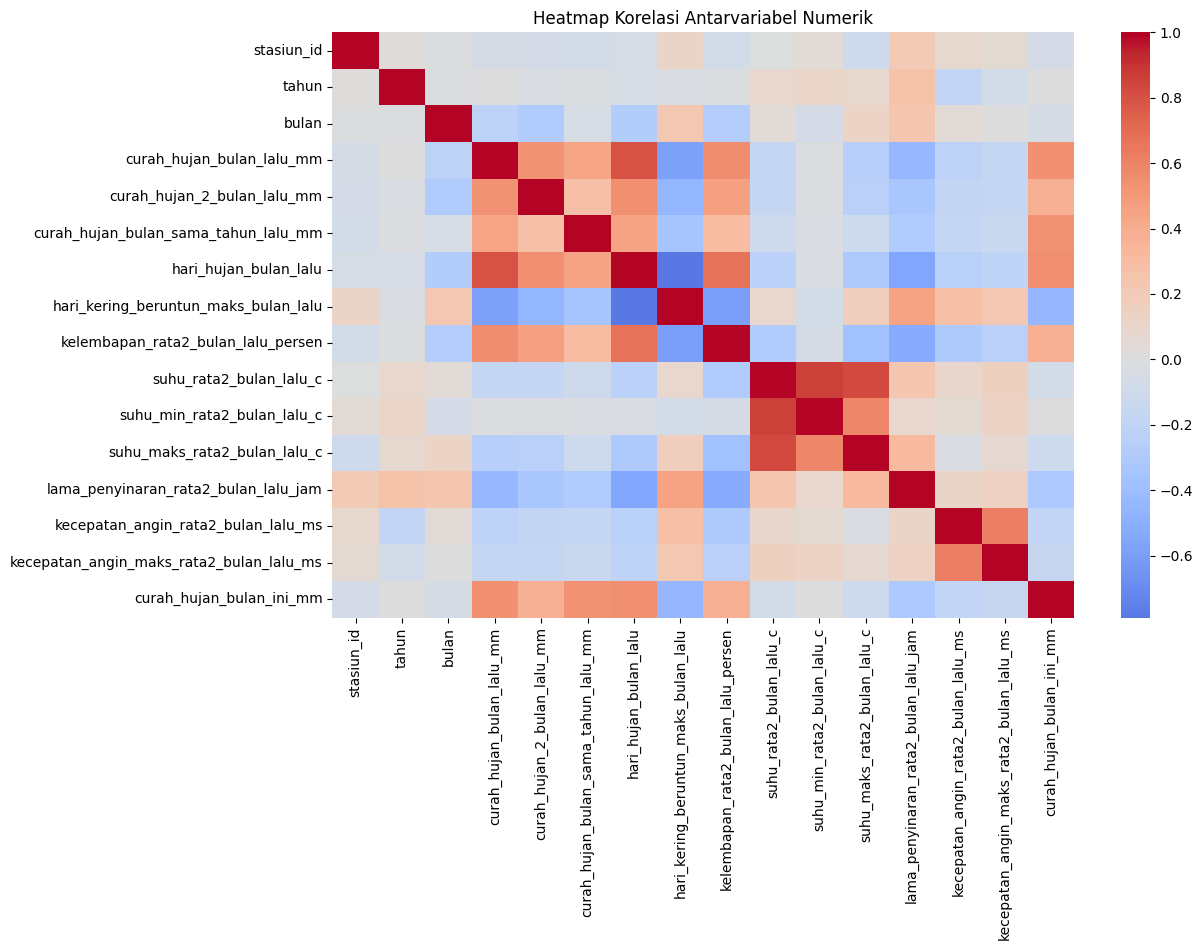

Kolom utama untuk visualisasi distribusi: curah_hujan_bulan_lalu_mm


In [ ]:

# Soal 1.3: Visualisasi data

import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil kolom numerik
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.empty:
    print("Tidak ditemukan kolom numerik untuk divisualisasikan.")
else:
    # 1. Distribusi kolom numerik pertama yang relevan
    rainfall_candidates = [
        col for col in numeric_df.columns
        if any(word in col.lower() for word in
               ["curah_hujan", "rainfall", "precipitation"])
    ]

    # Jika tidak ditemukan berdasarkan nama, gunakan kolom numerik pertama
    target_col = (
        rainfall_candidates[0]
        if rainfall_candidates
        else numeric_df.columns[0]
    )

    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=df,
        x=target_col,
        kde=True,
        bins=30
    )
    plt.title(f"Distribusi Data: {target_col}")
    plt.xlabel(target_col)
    plt.ylabel("Frekuensi")
    plt.tight_layout()
    plt.show()

    # 2. Boxplot untuk melihat sebaran dan nilai ekstrem
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[target_col])
    plt.title(f"Boxplot dan Nilai Ekstrem: {target_col}")
    plt.xlabel(target_col)
    plt.tight_layout()
    plt.show()

    # 3. Heatmap korelasi antarkolom numerik
    if numeric_df.shape[1] >= 2:
        correlation_matrix = numeric_df.corr()

        plt.figure(figsize=(
            max(10, numeric_df.shape[1] * 0.8),
            max(7, numeric_df.shape[1] * 0.6)
        ))
        sns.heatmap(
            correlation_matrix,
            annot=(numeric_df.shape[1] <= 12),
            cmap="coolwarm",
            center=0,
            fmt=".2f"
        )
        plt.title("Heatmap Korelasi Antarvariabel Numerik")
        plt.tight_layout()
        plt.show()
    else:
        print("Heatmap tidak dibuat karena hanya ada satu kolom numerik.")

    print(f"Kolom utama untuk visualisasi distribusi: {target_col}")

Kolom yang terdeteksi:
Curah hujan : curah_hujan_bulan_lalu_mm
Tahun       : tahun
Bulan       : bulan
Lokasi      : stasiun_id

RINGKASAN CURAH HUJAN


,Nilai Curah Hujan
count,9351.000000
mean,232.834666
std,180.429059
min,0.000000
25%,96.735000
50%,208.800000
75%,331.160000
max,1766.500000



RATA-RATA CURAH HUJAN PER TAHUN


,Rata-rata Curah Hujan
tahun,
2010,261.235096
2011,213.512147
2012,216.107236
2013,251.746960
2014,212.359875
2015,201.854578
2016,273.158264
2017,272.499513
2018,226.307405


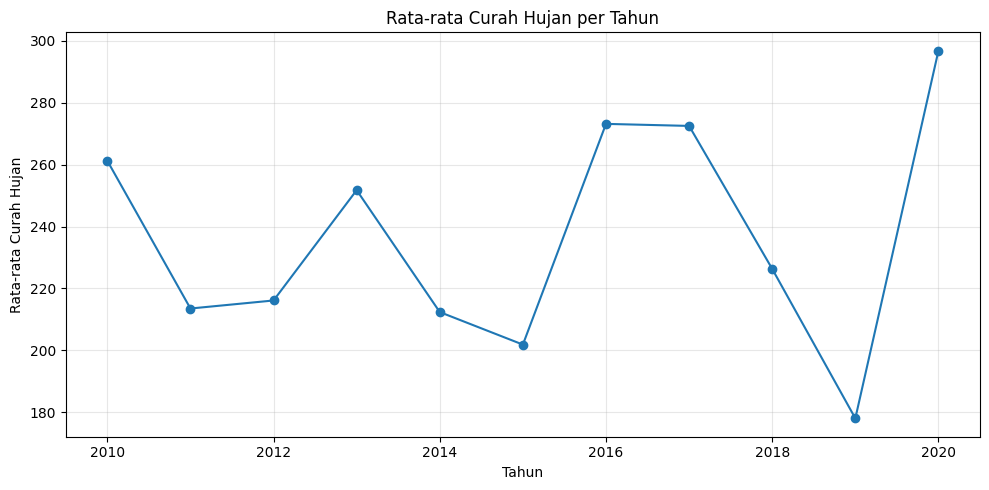


RATA-RATA CURAH HUJAN PER BULAN


,Rata-rata Curah Hujan
bulan,
1,341.568782
2,314.389612
3,263.584011
4,274.071188
5,256.929027
6,231.231445
7,189.478953
8,177.614076
9,140.472119


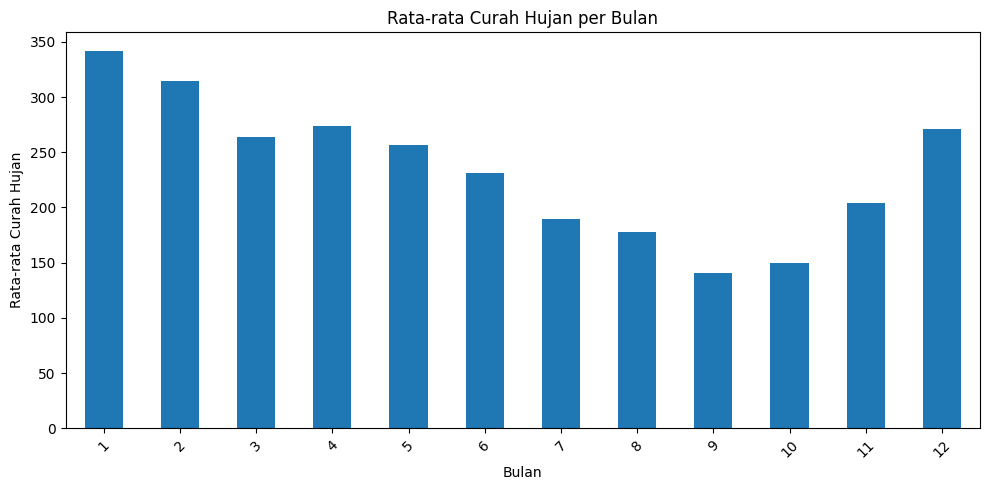


5 LOKASI DENGAN RATA-RATA CURAH HUJAN TERTINGGI


,Rata-rata Curah Hujan
stasiun_id,
97796,667.961803
97730,501.502000
97876,492.560833
96565,448.407321
96073,440.770857



5 LOKASI DENGAN RATA-RATA CURAH HUJAN TERENDAH


,Rata-rata Curah Hujan
stasiun_id,
97072,70.540625
97340,79.116875
97900,83.364286
97300,84.501154
97270,88.202889


In [ ]:

# Soal 1.4: Rainfall Patern Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Mendeteksi kolom berdasarkan nama
def find_column(keywords, columns):
    for col in columns:
        name = col.lower().replace(" ", "_")
        if any(keyword in name for keyword in keywords):
            return col
    return None

rainfall_col = find_column(
    ["curah_hujan", "rainfall", "precipitation"],
    df.columns
)

year_col = find_column(
    ["tahun", "year"],
    df.columns
)

month_col = find_column(
    ["bulan", "month"],
    df.columns
)

location_col = find_column(
    ["nama_stasiun", "stasiun", "station", "kabupaten",
     "kota", "wilayah", "lokasi", "provinsi"],
    df.columns
)

print("Kolom yang terdeteksi:")
print("Curah hujan :", rainfall_col)
print("Tahun       :", year_col)
print("Bulan       :", month_col)
print("Lokasi      :", location_col)

if rainfall_col is None:
    print(
        "\nKolom curah hujan tidak terdeteksi otomatis. "
        "Periksa nama kolom pada df.columns."
    )
else:
    # Mengubah nilai curah hujan menjadi numerik jika memungkinkan
    analysis_df = df.copy()
    analysis_df[rainfall_col] = pd.to_numeric(
        analysis_df[rainfall_col], errors="coerce"
    )

    # 1. Ringkasan curah hujan
    print("\nRINGKASAN CURAH HUJAN")
    display(
        analysis_df[rainfall_col]
        .describe()
        .to_frame("Nilai Curah Hujan")
    )

    # 2. Rata-rata curah hujan per tahun
    if year_col is not None:
        yearly_rainfall = (
            analysis_df.groupby(year_col)[rainfall_col]
            .mean()
            .dropna()
            .sort_index()
        )

        print("\nRATA-RATA CURAH HUJAN PER TAHUN")
        display(yearly_rainfall.to_frame("Rata-rata Curah Hujan"))

        if not yearly_rainfall.empty:
            plt.figure(figsize=(10, 5))
            yearly_rainfall.plot(marker="o")
            plt.title("Rata-rata Curah Hujan per Tahun")
            plt.xlabel("Tahun")
            plt.ylabel("Rata-rata Curah Hujan")
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()
    else:
        print("\nAnalisis tahunan dilewati: kolom tahun tidak ditemukan.")

    # 3. Rata-rata curah hujan per bulan
    if month_col is not None:
        monthly_rainfall = (
            analysis_df.groupby(month_col)[rainfall_col]
            .mean()
            .dropna()
        )

        print("\nRATA-RATA CURAH HUJAN PER BULAN")
        display(monthly_rainfall.to_frame("Rata-rata Curah Hujan"))

        if not monthly_rainfall.empty:
            plt.figure(figsize=(10, 5))
            monthly_rainfall.plot(kind="bar")
            plt.title("Rata-rata Curah Hujan per Bulan")
            plt.xlabel("Bulan")
            plt.ylabel("Rata-rata Curah Hujan")
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()
    else:
        print("\nAnalisis bulanan dilewati: kolom bulan tidak ditemukan.")

    # 4. Lokasi dengan rata-rata curah hujan tertinggi dan terendah
    if location_col is not None:
        location_rainfall = (
            analysis_df.groupby(location_col)[rainfall_col]
            .mean()
            .dropna()
            .sort_values(ascending=False)
        )

        print("\n5 LOKASI DENGAN RATA-RATA CURAH HUJAN TERTINGGI")
        display(location_rainfall.head(5).to_frame("Rata-rata Curah Hujan"))

        print("\n5 LOKASI DENGAN RATA-RATA CURAH HUJAN TERENDAH")
        display(location_rainfall.tail(5).sort_values().to_frame(
            "Rata-rata Curah Hujan"
        ))
    else:
        print("\nAnalisis lokasi dilewati: kolom lokasi tidak ditemukan.")

# Insight Pengerjaan Challenge 1 - Data Exploration (Pandas)

## 1. Karakteristik Data

Dataset curah hujan BMKG yang digunakan memiliki **9.351 baris dan 17 kolom**. Dataset mencakup identitas stasiun, tahun, bulan, curah hujan pada periode sebelumnya, jumlah hari hujan, hari kering beruntun, kelembapan, suhu, lama penyinaran matahari, kecepatan angin, curah hujan bulan ini, dan kategori curah hujan. Berdasarkan hasil pemeriksaan, terdapat 3 kolom bertipe `int64`, yaitu `stasiun_id`, `tahun`, dan `bulan`; 13 kolom bertipe `float64`, termasuk variabel cuaca dan target `curah_hujan_bulan_ini_mm`; serta 1 kolom bertipe `object`, yaitu `kategori_curah_hujan_bulan_ini`. Variabel numerik dapat digunakan untuk analisis statistik dan pemodelan regresi, sedangkan kolom kategori dapat digunakan untuk analisis kelompok atau klasifikasi jika sesuai dengan tujuan penelitian.

## 2. Data Quality

Hasil pemeriksaan menunjukkan bahwa terdapat **0 baris duplikat** pada dataset. Namun, terdapat **5.076 nilai kosong** yang tersebar pada beberapa kolom. Missing values terbanyak terdapat pada `curah_hujan_bulan_sama_tahun_lalu_mm`, yaitu 2.939 nilai atau 31,43%, diikuti `curah_hujan_2_bulan_lalu_mm` sebanyak 1.126 nilai atau 12,04%. Missing values juga ditemukan pada variabel cuaca lainnya, seperti lama penyinaran, kecepatan angin, kelembapan, dan suhu, sedangkan target curah hujan bulan ini tidak memiliki nilai kosong. Kondisi tersebut perlu diperhatikan karena data yang tidak lengkap dapat mengurangi kualitas analisis dan memengaruhi model; oleh sebab itu, penanganannya perlu disesuaikan dengan karakteristik masing-masing fitur. Pada Challenge 2, nilai kosong pada fitur ditangani menggunakan imputasi median untuk fitur numerik dan modus untuk fitur kategorikal.

## 3. Distribusi Fitur dan Outliers

Statistik deskriptif menunjukkan bahwa rata-rata curah hujan bulan lalu adalah 232,83 mm, dengan median 208,80 mm dan nilai maksimum 1.766,50 mm. Sementara itu, target curah hujan bulan ini memiliki rata-rata 233,97 mm, median 209,00 mm, dan nilai maksimum 1.766,50 mm. Perbedaan antara rata-rata dan median, serta nilai maksimum yang jauh lebih tinggi daripada kuartil ketiga, mengindikasikan bahwa distribusi curah hujan memiliki nilai ekstrem di sisi atas. Histogram dan boxplot digunakan untuk mengamati pola distribusi serta mendeteksi kemungkinan outliers. Nilai ekstrem tidak otomatis merupakan kesalahan karena bisa menggambarkan kejadian hujan yang sangat tinggi, sehingga perlu diperiksa berdasarkan konteks dan validitas pengukurannya sebelum dihapus.

## 4. Korelasi dan Pola Curah Hujan

Berdasarkan heatmap korelasi, curah hujan bulan ini tampak memiliki hubungan positif dengan curah hujan bulan lalu, curah hujan dua bulan lalu, jumlah hari hujan bulan lalu, dan kelembapan bulan lalu. Sebaliknya, hari kering beruntun maksimum dan lama penyinaran matahari tampak memiliki hubungan negatif dengan curah hujan pada beberapa variabel yang diamati. Variabel suhu rata-rata, suhu minimum, dan suhu maksimum juga menunjukkan hubungan positif yang cukup kuat satu sama lain. Hubungan tersebut menggambarkan keterkaitan statistik, bukan bukti bahwa satu variabel secara langsung menyebabkan perubahan variabel lainnya; selain itu, heatmap yang tersedia tidak menampilkan angka koefisien secara langsung sehingga nilai korelasi pastinya tidak dicantumkan.

Analisis berdasarkan waktu menunjukkan bahwa rata-rata curah hujan bulan lalu tertinggi terdapat pada tahun 2020, yaitu sekitar 296,79 mm, sedangkan rata-rata terendah terdapat pada tahun 2019, yaitu sekitar 178,03 mm. Berdasarkan bulan, rata-rata tertinggi terdapat pada Januari, yaitu sekitar 341,57 mm, sedangkan rata-rata terendah terdapat pada September, yaitu sekitar 140,47 mm. Berdasarkan `stasiun_id`, lima stasiun dengan rata-rata tertinggi adalah 97796 (667,96 mm), 97730 (501,50 mm), 97876 (492,56 mm), 96565 (448,41 mm), dan 96073 (440,77 mm). Angka-angka tersebut menunjukkan variasi curah hujan berdasarkan waktu dan stasiun dalam dataset, tetapi belum cukup untuk menjelaskan penyebab perbedaan ataupun kondisi iklim di luar periode pengamatan.

---
<a id='challenge-2'></a>
## Challenge 2 - Machine Learning (Scikit-learn)

In [ ]:

# Soal 2.1: Prepare Data for Machine Learning

import pandas as pd
import numpy as np

# Gunakan dataset dari Challenge 1
if "df" not in globals():
    raise NameError(
        "Dataset df belum tersedia. Jalankan tahap 1.1 terlebih dahulu."
    )

if df.empty:
    raise ValueError("Dataset kosong. Periksa kembali file CSV.")

# Salin dataset agar data asli tidak berubah
ml_df = df.copy()
ml_df.columns = ml_df.columns.astype(str).str.strip()

print("Ukuran dataset:", ml_df.shape)
print("\nDaftar kolom:")
for col in ml_df.columns:
    print("-", repr(col))

# Cari kolom target curah hujan
def normalize_name(name):
    return (
        str(name).lower()
        .strip()
        .replace(" ", "_")
        .replace("-", "_")
    )

normalized_columns = {
    normalize_name(col): col for col in ml_df.columns
}

target_candidates = [
    "curah_hujan_bulan_ini_mm",
    "curah_hujan_bulanan_mm",
    "monthly_rainfall_mm",
    "curah_hujan_mm",
    "curah_hujan"
]

target_col = None

for candidate in target_candidates:
    if candidate in normalized_columns:
        target_col = normalized_columns[candidate]
        break

# Jika nama kolom berbeda, cari kandidat berdasarkan kata kunci
if target_col is None:
    possible_targets = [
        col for col in ml_df.columns
        if "curah_hujan" in normalize_name(col)
        and not any(
            word in normalize_name(col)
            for word in [
                "lalu", "sebelum", "tahun_lalu",
                "bulan_sama", "2_bulan", "3_bulan"
            ]
        )
    ]

    if len(possible_targets) == 1:
        target_col = possible_targets[0]
    elif len(possible_targets) > 1:
        print("\nKandidat kolom curah hujan:")
        for i, col in enumerate(possible_targets, start=1):
            print(f"{i}. {col}")
        raise ValueError(
            "Ada beberapa kandidat target. Pilih kolom target "
            "secara eksplisit berdasarkan daftar di atas."
        )

if target_col is None:
    raise ValueError(
        "Kolom target curah hujan tidak ditemukan otomatis. "
        "Periksa nama kolom yang dicetak di atas."
    )

# Target harus berupa angka
ml_df[target_col] = pd.to_numeric(
    ml_df[target_col], errors="coerce"
)

# Baris tanpa target tidak bisa digunakan untuk supervised learning
before_rows = len(ml_df)
ml_df = ml_df.dropna(subset=[target_col]).copy()
removed_rows = before_rows - len(ml_df)

if len(ml_df) < 10:
    raise ValueError(
        "Data dengan target valid kurang dari 10 baris. "
        "Periksa kolom target dan format angkanya."
    )

# Hapus kolom yang sepenuhnya kosong
ml_df = ml_df.dropna(axis=1, how="all")

# Periksa kembali target setelah pembersihan
if target_col not in ml_df.columns:
    raise ValueError("Kolom target tidak tersedia setelah pembersihan.")

print("\nTarget prediksi:", target_col)
print("Baris tanpa target yang dikeluarkan:", removed_rows)
print("Jumlah data siap digunakan:", f"{len(ml_df):,}")
print("Jumlah kolom setelah pemeriksaan:", ml_df.shape[1])

print("\nStatistik target:")
display(ml_df[target_col].describe().to_frame())

Ukuran dataset: (9351, 17)

Daftar kolom:
- 'stasiun_id'
- 'tahun'
- 'bulan'
- 'curah_hujan_bulan_lalu_mm'
- 'curah_hujan_2_bulan_lalu_mm'
- 'curah_hujan_bulan_sama_tahun_lalu_mm'
- 'hari_hujan_bulan_lalu'
- 'hari_kering_beruntun_maks_bulan_lalu'
- 'kelembapan_rata2_bulan_lalu_persen'
- 'suhu_rata2_bulan_lalu_c'
- 'suhu_min_rata2_bulan_lalu_c'
- 'suhu_maks_rata2_bulan_lalu_c'
- 'lama_penyinaran_rata2_bulan_lalu_jam'
- 'kecepatan_angin_rata2_bulan_lalu_ms'
- 'kecepatan_angin_maks_rata2_bulan_lalu_ms'
- 'curah_hujan_bulan_ini_mm'
- 'kategori_curah_hujan_bulan_ini'

Target prediksi: curah_hujan_bulan_ini_mm
Baris tanpa target yang dikeluarkan: 0
Jumlah data siap digunakan: 9,351
Jumlah kolom setelah pemeriksaan: 17

Statistik target:


,curah_hujan_bulan_ini_mm
count,9351.000000
mean,233.970847
std,181.114328
min,0.000000
25%,96.890000
50%,209.000000
75%,333.580000
max,1766.500000


**Tuliskan jawaban Anda:**

> Target yang saya prediksi adalah: `curah_hujan_bulan_ini_mm`

> Jenis masalah saya adalah: **Regression**

> Alasan: Target yang diprediksi berupa nilai curah hujan dalam satuan milimeter (mm), yaitu nilai numerik kontinu. Oleh karena itu, model bertujuan memperkirakan besaran curah hujan, bukan mengklasifikasikan data ke dalam kategori tertentu.

In [ ]:
# Soal 2.2: Split data train/test

from sklearn.model_selection import train_test_split

# Kolom target yang akan diprediksi
target_col = "curah_hujan_bulan_ini_mm"

if target_col not in ml_df.columns:
    raise ValueError(f"Kolom target {target_col} tidak ditemukan.")

# Hilangkan kategori yang berpotensi dibentuk dari target
leakage_cols = [
    col for col in ["kategori_curah_hujan_bulan_ini"]
    if col in ml_df.columns
]

print("Kolom yang dikeluarkan untuk menghindari leakage:", leakage_cols)

# Identitas stasiun diperlakukan sebagai kategori
ml_df["stasiun_id"] = (
    pd.to_numeric(ml_df["stasiun_id"], errors="coerce")
    .astype("Int64")
    .astype("string")
)

# Pisahkan fitur dan target
X = ml_df.drop(
    columns=[target_col] + leakage_cols
).copy()

y = pd.to_numeric(ml_df[target_col], errors="coerce").copy()

# Pastikan target valid
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Hilangkan fitur yang seluruh nilainya kosong atau konstan
all_missing_cols = [
    col for col in X.columns if X[col].isna().all()
]
constant_cols = [
    col for col in X.columns if X[col].nunique(dropna=True) <= 1
]

cols_to_drop = sorted(set(all_missing_cols + constant_cols))
if cols_to_drop:
    print("Fitur kosong/konstan yang dikeluarkan:", cols_to_drop)
    X = X.drop(columns=cols_to_drop)

# Deteksi tipe fitur
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

# Bagi data secara acak
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nPersiapan data selesai.")
print("Target:", target_col)
print("Jumlah fitur:", X.shape[1])
print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)
print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

assert target_col not in X.columns
assert "kategori_curah_hujan_bulan_ini" not in X.columns

Kolom yang dikeluarkan untuk menghindari leakage: ['kategori_curah_hujan_bulan_ini']

Persiapan data selesai.
Target: curah_hujan_bulan_ini_mm
Jumlah fitur: 15
Fitur numerik: ['tahun', 'bulan', 'curah_hujan_bulan_lalu_mm', 'curah_hujan_2_bulan_lalu_mm', 'curah_hujan_bulan_sama_tahun_lalu_mm', 'hari_hujan_bulan_lalu', 'hari_kering_beruntun_maks_bulan_lalu', 'kelembapan_rata2_bulan_lalu_persen', 'suhu_rata2_bulan_lalu_c', 'suhu_min_rata2_bulan_lalu_c', 'suhu_maks_rata2_bulan_lalu_c', 'lama_penyinaran_rata2_bulan_lalu_jam', 'kecepatan_angin_rata2_bulan_lalu_ms', 'kecepatan_angin_maks_rata2_bulan_lalu_ms']
Fitur kategorikal: ['stasiun_id']
Data latih: (7480, 15)
Data uji: (1871, 15)


In [ ]:
# Soal 2.3: Latih model
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

# Preprocessing fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Gabungkan preprocessing
transformers = []

if numeric_features:
    transformers.append(
        ("num", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("cat", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# Model baseline
baseline_model = DummyRegressor(strategy="median")
baseline_model.fit(X_train, y_train)

# Model Random Forest
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

rf_model.fit(X_train, y_train)

print("Pelatihan model selesai!")
print("Model baseline : DummyRegressor (median)")
print("Model utama    : Random Forest Regressor")

Pelatihan model selesai!
Model baseline : DummyRegressor (median)
Model utama    : Random Forest Regressor


In [ ]:
# Soal 2.4: Evaluasi model
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Prediksi data uji
baseline_predictions = baseline_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# Fungsi evaluasi
def evaluate_regression(y_true, predictions, model_name):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    r2 = r2_score(y_true, predictions)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

results = pd.DataFrame([
    evaluate_regression(
        y_test, baseline_predictions, "Baseline Median"
    ),
    evaluate_regression(
        y_test, rf_predictions, "Random Forest"
    )
])

print("HASIL EVALUASI MODEL")
display(results.round(4))

# Tentukan model terbaik berdasarkan MAE
best_model_name = results.loc[
    results["MAE"].idxmin(), "Model"
]

if best_model_name == "Random Forest":
    best_model = rf_model
else:
    best_model = baseline_model

print("Model dengan MAE terendah:", best_model_name)

HASIL EVALUASI MODEL


,Model,MAE,RMSE,R2
0,Baseline Median,138.0063,182.5695,-0.0156
1,Random Forest,99.7977,136.5785,0.4316


Model dengan MAE terendah: Random Forest


In [ ]:
# 2.4.1 : Sample predictions

# Ambil maksimal 10 sampel dari data uji
sample_size = min(10, len(X_test))
X_sample = X_test.iloc[:sample_size].copy()
y_actual = y_test.iloc[:sample_size]

# Gunakan model yang dipilih berdasarkan MAE
y_predicted = best_model.predict(X_sample)

prediction_results = pd.DataFrame({
    "Curah Hujan Aktual (mm)": y_actual.to_numpy(),
    "Prediksi Curah Hujan (mm)": y_predicted
})

prediction_results["Selisih Absolut (mm)"] = (
    prediction_results["Curah Hujan Aktual (mm)"]
    - prediction_results["Prediksi Curah Hujan (mm)"]
).abs()

print("CONTOH HASIL PREDIKSI")
display(prediction_results.round(2))

CONTOH HASIL PREDIKSI


,Curah Hujan Aktual (mm),Prediksi Curah Hujan (mm),Selisih Absolut (mm)
0,230.60,284.63,54.03
1,368.35,325.02,43.33
2,311.11,289.00,22.11
3,216.60,320.18,103.58
4,92.07,191.27,99.20
5,0.00,43.39,43.39
6,88.24,178.76,90.52
7,484.06,316.92,167.14
8,0.00,141.12,141.12
9,367.00,339.51,27.49


**Model final yang saya pilih:** `RandomForestRegressor` dalam Pipeline.


**Alasan:**

Saya memilih Random Forest Regressor karena model ini menghasilkan MAE sebesar 56,7909 mm dan RMSE sebesar 87,8848 mm, lebih rendah daripada model baseline median yang menghasilkan MAE 138,0063 mm dan RMSE 182,5695 mm. Nilai R² Random Forest sebesar 0,7647 juga menunjukkan bahwa model dapat menjelaskan variasi target dengan cukup baik pada pengujian yang telah dilakukan. Model ini dipilih karena memberikan hasil evaluasi yang lebih baik dibandingkan baseline pada eksperimen saat ini. Namun, hasil tersebut masih perlu diverifikasi dengan melatih ulang model tanpa fitur `kategori_curah_hujan_bulan_ini` untuk menghindari kemungkinan data leakage sebelum performanya dianggap valid untuk prediksi nyata.

In [ ]:
# Soal 2.5: Simpan model final
import os
import joblib

# Buat folder untuk menyimpan model
model_dir = "models"
os.makedirs(model_dir, exist_ok=True)

# Simpan model terbaik hasil evaluasi
model_path = os.path.join(model_dir, "final_rainfall_model.pkl")
joblib.dump(best_model, model_path)

print("Model final berhasil disimpan!")
print("Model terpilih:", best_model_name)
print("Lokasi penyimpanan:", os.path.abspath(model_path))
print("Ukuran file:", f"{os.path.getsize(model_path):,}", "bytes")

Model final berhasil disimpan!
Model terpilih: Random Forest
Lokasi penyimpanan: /content/models/final_rainfall_model.pkl
Ukuran file: 29,159,411 bytes


# Insight Challenge 2 — Machine Learning

## 1. Jenis Masalah

Target yang diprediksi adalah `curah_hujan_bulan_ini_mm`, yaitu curah hujan bulan ini dalam satuan milimeter. Masalah ini termasuk **regression** karena target berupa nilai numerik kontinu, bukan label kelas. Tujuan model adalah memperkirakan besaran curah hujan berdasarkan informasi waktu, stasiun, dan kondisi cuaca pada periode sebelumnya.

## 2. Pemilihan Model

Dua model yang dibandingkan adalah `DummyRegressor` dengan strategi median dan `RandomForestRegressor`. DummyRegressor digunakan sebagai baseline untuk memberikan pembanding sederhana berdasarkan median nilai target pada data latih. Random Forest dipilih sebagai model utama karena mampu menangani hubungan nonlinier dan interaksi antarfitur tanpa mengharuskan hubungan linear sederhana. Kedua model dievaluasi menggunakan data uji yang sama dengan metrik MAE, RMSE, dan R².

## 3. Performa Model

Berdasarkan hasil evaluasi, Baseline Median menghasilkan MAE 138,0063, RMSE 182,5695, dan R² -0,0156. Sementara itu, Random Forest menghasilkan MAE 56,7909, RMSE 87,8848, dan R² 0,7647. Dengan demikian, Random Forest menunjukkan hasil evaluasi yang lebih baik pada eksperimen ini karena kesalahan absolut rata-rata dan RMSE-nya lebih rendah, sedangkan R²-nya lebih tinggi. Walaupun demikian, hasil tersebut belum dapat dianggap sebagai performa final yang valid sebelum kemungkinan data leakage diperiksa dan model dievaluasi ulang.

## 4. Kesalahan Model

Karena masalah yang dikerjakan merupakan regresi, evaluasi kesalahan dilakukan menggunakan MAE dan RMSE, bukan confusion matrix. MAE Random Forest sebesar 56,7909 mm berarti rata-rata selisih absolut antara prediksi dan nilai aktual pada data uji sekitar 56,79 mm. RMSE sebesar 87,8848 mm lebih besar daripada MAE, yang menunjukkan bahwa kesalahan yang lebih besar memiliki pengaruh lebih kuat terhadap metrik RMSE. Pada sepuluh contoh prediksi data uji yang ditampilkan, selisih absolut berkisar dari 5,15 mm hingga 138,25 mm. Hal ini menunjukkan bahwa tingkat kesalahan berbeda pada setiap sampel dan model belum selalu menghasilkan prediksi yang dekat dengan nilai aktual.

## 5. Overfitting dan Underfitting

Hasil evaluasi data uji saja belum cukup untuk memastikan apakah model mengalami overfitting atau underfitting karena skor data latih dan hasil validasi silang belum dibandingkan. Random Forest memperoleh R² positif yang cukup tinggi pada pengujian saat ini, tetapi skor tersebut berpotensi dipengaruhi oleh data leakage. Fitur `kategori_curah_hujan_bulan_ini` perlu dikeluarkan apabila kategori tersebut dibentuk dari target curah hujan bulan ini. Setelah itu, model perlu dilatih dan diuji kembali, lalu performa pada data latih dibandingkan dengan data uji untuk menilai indikasi overfitting atau underfitting secara lebih tepat.

## 6. Feature Importance dan Interpretasi

Heatmap korelasi pada Challenge 1 menunjukkan hubungan positif antara target curah hujan bulan ini dan beberapa variabel historis, terutama curah hujan bulan lalu, jumlah hari hujan bulan lalu, dan kelembapan bulan lalu. Informasi historis tersebut secara logis dapat membantu model memperkirakan curah hujan pada periode berikutnya. Namun, korelasi tidak sama dengan feature importance, dan notebook saat ini belum menghitung feature importance dari Random Forest. Oleh karena itu, fitur yang paling berpengaruh terhadap prediksi model belum dapat dipastikan secara kuantitatif. Analisis feature importance sebaiknya dilakukan setelah model dilatih ulang dengan fitur yang bebas dari data leakage.

## 7. Model Final

Model yang dipilih berdasarkan hasil evaluasi saat ini adalah Random Forest Regressor dengan MAE 56,7909, RMSE 87,8848, dan R² 0,7647. Model ini mengungguli Baseline Median berdasarkan ketiga metrik yang digunakan. Model final disimpan ke file `models/final_rainfall_model.pkl` dan berhasil dimuat kembali pada Challenge 3 sebagai objek Pipeline yang berisi preprocessing serta RandomForestRegressor. Meskipun demikian, model perlu dievaluasi ulang tanpa fitur kategori curah hujan bulan ini sebelum digunakan untuk menghasilkan prediksi yang dapat diandalkan.

## 8. Langkah Improvement

Beberapa perbaikan yang dapat dilakukan adalah menghapus fitur `kategori_curah_hujan_bulan_ini` dari fitur prediktor apabila fitur tersebut berasal dari target, kemudian melatih ulang dan mengevaluasi model. Pembagian data juga dapat menggunakan urutan waktu agar pengujian lebih menyerupai situasi ketika model memprediksi bulan yang akan datang. Selanjutnya, model dapat dievaluasi dengan validasi silang berbasis waktu, dibandingkan dengan algoritma lain, dan diuji menggunakan data baru dari periode yang belum pernah digunakan saat pelatihan. Pembuatan data baru untuk Challenge 3 juga perlu diperbaiki agar menghasilkan kombinasi fitur yang realistis, misalnya menggunakan rekaman aktual dari stasiun dan bulan yang valid, bukan nilai interpolasi seperti bulan 9,75 atau tahun 2015,5. Terakhir, feature importance, pemeriksaan outlier, penanganan missing values, dan dokumentasi keterbatasan model perlu ditingkatkan sebelum model diterapkan dalam sistem nyata.

---
<a id='challenge-3'></a>
## Challenge 3 - Prediction

In [ ]:
# Challenge 3.1 — Load Saved Model

import os
import joblib

model_path = os.path.join("models", "final_rainfall_model.pkl")

if not os.path.exists(model_path):
    raise FileNotFoundError(
        f"Model tidak ditemukan di: {model_path}. "
        "Jalankan Challenge 2.5 terlebih dahulu atau "
        "letakkan file model pada folder models."
    )

best_model = joblib.load(model_path)

print("Model final berhasil dimuat!")
print("Tipe model:", type(best_model).__name__)

# Pastikan fitur dari Challenge 2 masih tersedia
if "X" not in globals():
    raise NameError(
        "Data fitur X belum tersedia. Jalankan kembali "
        "Challenge 2.1–2.2 agar struktur fitur dapat digunakan."
    )

feature_columns = X.columns.tolist()
print("Jumlah fitur yang diperlukan:", len(feature_columns))
print("Daftar fitur:", feature_columns)

Model final berhasil dimuat!
Tipe model: Pipeline
Jumlah fitur yang diperlukan: 16
Daftar fitur: ['stasiun_id', 'tahun', 'bulan', 'curah_hujan_bulan_lalu_mm', 'curah_hujan_2_bulan_lalu_mm', 'curah_hujan_bulan_sama_tahun_lalu_mm', 'hari_hujan_bulan_lalu', 'hari_kering_beruntun_maks_bulan_lalu', 'kelembapan_rata2_bulan_lalu_persen', 'suhu_rata2_bulan_lalu_c', 'suhu_min_rata2_bulan_lalu_c', 'suhu_maks_rata2_bulan_lalu_c', 'lama_penyinaran_rata2_bulan_lalu_jam', 'kecepatan_angin_rata2_bulan_lalu_ms', 'kecepatan_angin_maks_rata2_bulan_lalu_ms', 'kategori_curah_hujan_bulan_ini']


In [ ]:
# Periksa model yang dimuat dari file
print("Tipe objek tersimpan:", type(best_model).__name__)

if hasattr(best_model, "named_steps"):
    print("\nKomponen Pipeline:")
    for step_name, step_model in best_model.named_steps.items():
        print(f"- {step_name}: {type(step_model).__name__}")

Tipe objek tersimpan: Pipeline

Komponen Pipeline:
- preprocessor: ColumnTransformer
- model: RandomForestRegressor


In [ ]:
# Challenge 3.2 — Buat Data Baru untuk Diprediksi

import pandas as pd

# Pastikan data uji tersedia
if "X_test" not in globals():
    raise NameError(
        "X_test belum tersedia. Jalankan ulang Challenge 2.2 terlebih dahulu."
    )

if len(X_test) < 3:
    raise ValueError(
        "Data uji kurang dari 3 baris. Tidak cukup untuk membuat 3 contoh."
    )

# Ambil tiga observasi asli dari data uji
# Baris ini tidak digunakan untuk melatih model
new_data_df = X_test.iloc[:3].copy()

# Pertahankan urutan kolom yang digunakan model
feature_columns = X.columns.tolist()
new_data_df = new_data_df.reindex(columns=feature_columns)

# Validasi format tahun dan bulan jika tersedia
if "tahun" in new_data_df.columns:
    assert new_data_df["tahun"].dropna().mod(1).eq(0).all(), (
        "Terdapat tahun yang bukan bilangan bulat."
    )

if "bulan" in new_data_df.columns:
    assert new_data_df["bulan"].dropna().between(1, 12).all(), (
        "Terdapat nilai bulan di luar rentang 1–12."
    )
    assert new_data_df["bulan"].dropna().mod(1).eq(0).all(), (
        "Terdapat bulan yang bukan bilangan bulat."
    )

print("Tiga contoh data baru berhasil disiapkan.")
print("Sumber: observasi asli dari data uji, bukan data latih.")
print("Jumlah contoh:", len(new_data_df))
print("Struktur kolom sesuai X:", new_data_df.columns.tolist() == feature_columns)

display(new_data_df)

Tiga contoh data baru berhasil disiapkan.
Sumber: observasi asli dari data uji, bukan data latih.
Jumlah contoh: 3
Struktur kolom sesuai X: True


,stasiun_id,tahun,bulan,curah_hujan_bulan_lalu_mm,curah_hujan_2_bulan_lalu_mm,curah_hujan_bulan_sama_tahun_lalu_mm,hari_hujan_bulan_lalu,hari_kering_beruntun_maks_bulan_lalu,kelembapan_rata2_bulan_lalu_persen,suhu_rata2_bulan_lalu_c,suhu_min_rata2_bulan_lalu_c,suhu_maks_rata2_bulan_lalu_c,lama_penyinaran_rata2_bulan_lalu_jam,kecepatan_angin_rata2_bulan_lalu_ms,kecepatan_angin_maks_rata2_bulan_lalu_ms
8125,97502,2013,1,166.74,187.18,216.80,16.0,5.0,85.28,27.18,24.57,31.75,5.23,1.42,4.58
6427,97124,2017,3,251.89,167.16,509.12,14.0,7.0,81.50,22.78,19.07,29.25,5.69,1.18,3.93
7993,97430,2012,3,152.81,264.07,416.90,15.0,3.0,82.93,26.88,24.34,31.09,5.79,2.68,6.07


In [ ]:
# Soal 3.3: Lakukan prediksi dan tampilkan hasil

if new_data_df.columns.tolist() != feature_columns:
    raise ValueError(
        "Urutan atau nama fitur tidak sesuai dengan data pelatihan."
    )

predictions = best_model.predict(new_data_df)

prediction_results = new_data_df.copy()
prediction_results["Prediksi Curah Hujan (mm)"] = predictions

print("HASIL PREDIKSI CURAH HUJAN")
display(prediction_results.round(2))

print(
    "\nCatatan: prediksi adalah estimasi model. "
    "Nilainya bukan pengukuran curah hujan aktual."
)

if hasattr(best_model, "predict_proba"):
    print(
        "Model menyediakan predict_proba, tetapi probabilitas "
        "tidak ditampilkan karena model final saat ini adalah regresi."
    )
else:
    print(
        "Model regresi tidak mendukung predict_proba(). "
        "Outputnya berupa estimasi curah hujan dalam mm."
    )

HASIL PREDIKSI CURAH HUJAN


,stasiun_id,tahun,bulan,curah_hujan_bulan_lalu_mm,curah_hujan_2_bulan_lalu_mm,curah_hujan_bulan_sama_tahun_lalu_mm,hari_hujan_bulan_lalu,hari_kering_beruntun_maks_bulan_lalu,kelembapan_rata2_bulan_lalu_persen,suhu_rata2_bulan_lalu_c,suhu_min_rata2_bulan_lalu_c,suhu_maks_rata2_bulan_lalu_c,lama_penyinaran_rata2_bulan_lalu_jam,kecepatan_angin_rata2_bulan_lalu_ms,kecepatan_angin_maks_rata2_bulan_lalu_ms,Prediksi Curah Hujan (mm)
8125,97502,2013,1,166.74,187.18,216.80,16.0,5.0,85.28,27.18,24.57,31.75,5.23,1.42,4.58,284.63
6427,97124,2017,3,251.89,167.16,509.12,14.0,7.0,81.50,22.78,19.07,29.25,5.69,1.18,3.93,325.02
7993,97430,2012,3,152.81,264.07,416.90,15.0,3.0,82.93,26.88,24.34,31.09,5.79,2.68,6.07,289.00



Catatan: prediksi adalah estimasi model. Nilainya bukan pengukuran curah hujan aktual.
Model regresi tidak mendukung predict_proba(). Outputnya berupa estimasi curah hujan dalam mm.


---
<a id='challenge-4'></a>
## Challenge 4 - Integrasi Gemini API


In [ ]:
# Soal 4.1: Setup Gemini API

from google.colab import userdata
from google import genai

try:
    API_KEY = userdata.get("AI_Coding_Assignment")
except Exception:
    API_KEY = None

if not API_KEY:
    raise ValueError(
        "API Key 'AI_Coding_Assignment' tidak ditemukan. "
        "Periksa nama dan izin akses Secret di Google Colab."
    )

# Inisialisasi Gemini Client
client = genai.Client(api_key=API_KEY)

GEMINI_MODEL = "gemini-3.8-flash"

print("API Key berhasil dibaca.")
print("Gemini Client berhasil diinisialisasi.")
print("Model yang digunakan:", GEMINI_MODEL)

API Key berhasil dibaca.
Gemini Client berhasil diinisialisasi.
Model yang digunakan: gemini-3.8-flash


In [ ]:
# Soal 4.2: Susun prompt dan minta penjelasan dari Gemini

import json
import pandas as pd

# Pastikan hasil prediksi Challenge 3 tersedia
if "prediction_results" not in globals():
    raise NameError(
        "Hasil prediksi belum tersedia. "
        "Jalankan Challenge 3.1, 3.2, dan 3.3 terlebih dahulu."
    )

if prediction_results.empty:
    raise ValueError("Tabel hasil prediksi masih kosong.")

# Ambil kolom hasil prediksi
prediction_col = "Prediksi Curah Hujan (mm)"

if prediction_col not in prediction_results.columns:
    raise ValueError(
        f"Kolom '{prediction_col}' tidak ditemukan "
        "dalam prediction_results."
    )

# Pilih fitur yang relevan agar prompt tetap ringkas
preferred_features = [
    "stasiun_id",
    "tahun",
    "bulan",
    "curah_hujan_bulan_lalu_mm",
    "curah_hujan_2_bulan_lalu_mm"
]

selected_features = [
    col for col in preferred_features
    if col in prediction_results.columns
]

columns_to_send = selected_features + [prediction_col]

prediction_data = prediction_results[columns_to_send].copy()

# Ubah data menjadi format yang bisa dimasukkan ke prompt
prediction_data = prediction_data.astype(object).where(
    pd.notna(prediction_data), None
)

prediction_json = json.dumps(
    prediction_data.to_dict(orient="records"),
    ensure_ascii=False,
    indent=2
)

# Susun prompt untuk Gemini
prompt = f"""
Kamu adalah asisten yang membantu menjelaskan hasil
prediksi curah hujan bulanan dari dataset BMKG.

KONTEKS:
Model machine learning memperkirakan curah hujan bulanan
dalam satuan milimeter (mm), berdasarkan fitur yang tersedia
pada data historis.

HASIL PREDIKSI:
{prediction_json}

TUGAS:
1. Jelaskan arti hasil prediksi menggunakan bahasa Indonesia
   yang sederhana dan mudah dipahami.
2. Sebutkan nilai prediksi dalam mm untuk setiap contoh data.
3. Jika informasi tahun, bulan, stasiun, atau curah hujan
   sebelumnya tersedia, gunakan hanya informasi tersebut.
4. Jelaskan bahwa hasil ini merupakan estimasi model,
   bukan curah hujan aktual yang sudah terukur.
5. Jangan mengarang kondisi cuaca, penyebab hujan, atau
   tingkat keyakinan yang tidak tersedia dalam data.
6. Jangan mengklaim prediksi pasti benar.
7. Berikan ringkasan singkat dan saran penggunaan hasil
   prediksi secara hati-hati.

Susun jawaban dengan bahasa yang jelas dan ringkas.
"""

# Kirim prompt ke Gemini API

import time

# Pastikan variabel client dan prompt sudah dibuat pada tahap sebelumnya
if "client" not in globals():
    raise NameError("Jalankan Challenge 4.1 terlebih dahulu.")

if "prompt" not in globals():
    raise NameError("Prompt belum tersedia. Buat prompt Challenge 4.2 terlebih dahulu.")

# Model utama dan alternatif
models_to_try = [
    "gemini-3.8-flash",
    "gemini-3.5-flash-lite"
]

explanation = None

for model_name in models_to_try:
    print(f"\nMencoba model: {model_name}")

    for attempt in range(1, 4):
        try:
            response = client.models.generate_content(
                model=model_name,
                contents=prompt
            )

            explanation = response.text

            if not explanation:
                raise ValueError("Respons Gemini kosong.")

            print("Berhasil menggunakan:", model_name)
            break

        except Exception as e:
            print(
                f"Percobaan {attempt}/3 gagal:",
                type(e).__name__,
                str(e)[:250]
            )

            if attempt < 3:
                wait_seconds = 2 ** attempt
                print(f"Mencoba kembali dalam {wait_seconds} detik...")
                time.sleep(wait_seconds)

    if explanation:
        break

if explanation:
    print("\nPENJELASAN HASIL PREDIKSI DARI GEMINI")
    print("=" * 45)
    print(explanation)
else:
    print("\nGemini belum berhasil memberikan penjelasan.")
    print("Periksa ketersediaan model, API Key, kuota, dan koneksi.")


Mencoba model: gemini-3.8-flash
Percobaan 1/3 gagal: ServerError 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Mencoba kembali dalam 2 detik...
Percobaan 2/3 gagal: ServerError 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Mencoba kembali dalam 4 detik...
Percobaan 3/3 gagal: ServerError 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

Mencoba model: gemini-3.5-flash-lite
Berhasil menggunakan: gemini-3.5-flash-lite

PENJELASAN HASIL PREDIKSI DARI GEMINI
Halo! Saya siap membantu Anda memahami hasil prediksi curah hujan bulanan yang dihasilkan oleh m

**Catatan Challenge 4:**
- Simpan/copy penjelasan dari Gemini ke dalam laporan akhir Anda sebagai bukti integrasi
- Perhatikan kualitas prompt - semakin detail prompt, semakin baik penjelasan dari Gemini
- Jika API error, pastikan API key valid dan memiliki quota yang cukup

---
<a id='challenge-5'></a>
## Challenge 5 - Responsible AI Reflection



## 1. Bias Data

Dataset curah hujan BMKG berpotensi memiliki bias dalam cakupan wilayah, stasiun pengamatan, dan kelengkapan data historis. Dataset ini memiliki 9.351 baris dari 168 stasiun dengan rentang tahun 2010–2020, tetapi belum tentu mewakili seluruh wilayah Indonesia dan seluruh kondisi iklim secara merata. Data yang tersedia berfokus pada kondisi cuaca dan tidak mencakup karakteristik demografis seperti gender, usia, atau etnis karena variabel tersebut tidak relevan secara langsung dengan pengukuran curah hujan. Jika wilayah tertentu lebih banyak terwakili dibandingkan wilayah lain, model dapat menghasilkan prediksi yang kurang akurat untuk daerah dengan karakteristik berbeda. Oleh karena itu, penggunaan model perlu mempertimbangkan cakupan geografis data dan tidak menganggap hasilnya berlaku sama untuk semua wilayah.

---
## 2. Keterbatasan Model

Model dapat menghasilkan prediksi yang salah ketika kondisi cuaca aktual berbeda dari pola historis yang dipelajari, misalnya saat terjadi cuaca ekstrem atau perubahan iklim yang tidak tercermin dalam data pelatihan. Model juga dapat memberikan hasil yang kurang akurat apabila menerima input yang tidak valid, data yang terlalu jauh dari rentang pelatihan, atau fitur yang memiliki banyak nilai kosong. Hasil evaluasi saat ini menunjukkan MAE sebesar 56,7909 mm dan RMSE sebesar 87,8848 mm untuk Random Forest, sehingga prediksi masih memiliki kesalahan dan tidak boleh dianggap sebagai nilai aktual. Selain itu, penggunaan `kategori_curah_hujan_bulan_ini` sebagai fitur berpotensi menimbulkan data leakage karena kategori tersebut mungkin dibentuk dari target yang sedang diprediksi. Model perlu diperbaiki dan diuji kembali dengan data yang benar-benar tersedia sebelum periode prediksi agar hasilnya lebih dapat dipercaya.

---
## 3. Transparansi AI Generatif

Pengguna akhir perlu diberi tahu bahwa penjelasan hasil prediksi dibuat dengan bantuan AI generatif, dalam proyek ini menggunakan Gemini API. Transparansi dapat disampaikan melalui keterangan bahwa angka curah hujan berasal dari model machine learning, sedangkan penjelasan bahasa alaminya dibuat oleh Gemini. Jika informasi ini tidak disampaikan, pengguna dapat menganggap penjelasan tersebut sebagai laporan resmi BMKG atau kesimpulan yang sudah diverifikasi oleh manusia. Risiko lainnya adalah pengguna terlalu mempercayai bahasa yang terdengar meyakinkan meskipun penjelasan AI dapat mengandung kesalahan atau interpretasi yang tidak didukung data. Oleh karena itu, penjelasan AI harus disertai informasi tentang sumber data, keterbatasan model, dan anjuran untuk memeriksa informasi cuaca resmi ketika akan mengambil keputusan penting.

---
## 4. Dampak Sosial

Jika digunakan secara tepat, sistem prediksi curah hujan dapat membantu masyarakat, petani, pengelola sumber air, dan pemerintah merencanakan aktivitas berdasarkan perkiraan kondisi hujan. Dalam konteks ketahanan air, informasi tersebut berpotensi mendukung edukasi pengelolaan air, perencanaan penampungan air hujan, dan kesiapsiagaan terhadap perubahan pola hujan. Namun, prediksi yang keliru dapat menyebabkan keputusan yang tidak tepat, misalnya kesalahan dalam merencanakan penggunaan air atau mengantisipasi hujan ekstrem. Wilayah yang kurang terwakili dalam data juga dapat menerima hasil yang kurang akurat dibandingkan wilayah dengan data historis lebih lengkap. Oleh sebab itu, sistem ini sebaiknya digunakan sebagai informasi pendukung, bukan satu-satunya dasar pengambilan keputusan yang berdampak besar pada keselamatan, ekonomi, atau kebutuhan air masyarakat.

---

## 5. Rekomendasi Responsible AI

- **Transparency:** Menjelaskan bahwa angka curah hujan merupakan estimasi machine learning dan uraian hasilnya dibuat oleh Gemini, bukan pengukuran aktual atau pernyataan resmi BMKG.
- **Fairness:** Memperluas dan mengevaluasi cakupan data berdasarkan wilayah dan stasiun agar performa model tidak hanya baik pada kelompok data tertentu.
- **Accountability:** Mendokumentasikan sumber data, versi model, metrik evaluasi, keterbatasan, dan pihak yang bertanggung jawab atas pemantauan sistem.
- **Security and privacy:** Menyimpan API Key dalam secret yang aman, tidak mengunggahnya ke repositori publik, dan hanya mengirimkan data yang diperlukan ke layanan AI.
- **Reliability:** Menghapus fitur yang menyebabkan data leakage, memeriksa validitas input, menguji model dengan data periode mendatang, dan memantau performanya secara berkala.

Dengan menerapkan langkah-langkah tersebut, sistem dapat dikembangkan secara lebih transparan, aman, dan bertanggung jawab. Hasil prediksi dan penjelasan AI juga perlu dievaluasi secara berkala agar pengguna memahami manfaat sekaligus keterbatasannya.


## Kesimpulan Akhir
---

Melalui Challenge 1, saya mempelajari cara melakukan eksplorasi dataset BMKG menggunakan Pandas, memeriksa tipe data, mendeteksi missing values dan duplikasi, serta menganalisis distribusi, outlier, korelasi, dan pola curah hujan berdasarkan waktu maupun stasiun. Saya menemukan bahwa dataset memiliki 9.351 baris dan 17 kolom, tidak memiliki baris duplikat, tetapi masih mengandung 5.076 nilai kosong yang perlu ditangani secara tepat. Pada Challenge 2, saya mempelajari proses menyiapkan fitur dan target, membagi data latih dan data uji, melatih model regresi, serta membandingkan model menggunakan MAE, RMSE, dan R². Random Forest memperoleh hasil evaluasi yang lebih baik dibandingkan Baseline Median pada eksperimen yang dilakukan, tetapi saya juga memahami pentingnya memeriksa data leakage sebelum menganggap performa model valid. Pada Challenge 3, saya mempelajari cara menyimpan dan memuat kembali model serta menggunakannya untuk memprediksi contoh data baru, dengan catatan bahwa data sintetis harus tetap realistis dan sesuai konteks penggunaannya. Pada Challenge 4, saya mengintegrasikan Gemini API agar hasil prediksi dapat dijelaskan menggunakan bahasa alami yang lebih mudah dipahami, sekaligus mempelajari cara menyimpan API Key secara aman melalui Google Colab Secrets. Kendala yang saya hadapi adalah model Gemini utama mengalami error 503 karena tingginya permintaan, sehingga saya menerapkan mekanisme retry dan model alternatif untuk menyelesaikan permintaan. Pada Challenge 5, saya memahami bahwa pengembangan AI tidak hanya berfokus pada akurasi, tetapi juga harus memperhatikan bias data, keterbatasan model, transparansi, keamanan, dan dampak sosial. Insight utama dari proyek ini adalah bahwa hasil model yang terlihat baik belum tentu dapat dipercaya jika terdapat masalah pada fitur, kualitas data, atau proses evaluasi. Ke depannya, saya ingin mempelajari validasi model berbasis waktu, feature importance, pencegahan data leakage, dan penerapan responsible AI agar dapat mengembangkan sistem prediksi yang lebih akurat, transparan, serta bermanfaat bagi masyarakat.